# Basic concepts: the vocabulary of the series, from simple to complex

This notebook is a reference for all the others: `cdma_sim`, `ldpc_sim`, `turbo_sim`, `lte_sim`, `ofdm_sim`, `lora_sim`, `ocusync_sim`, `transforms_sim`, `otfs_sim`, `zak_sim`, `afdm_sim`, `ocdm_sim`, `otsm_sim`. The terms are collected from them and arranged into 12 levels, each building on the previous ones. Every level gives short definitions with formulas and "where it appears" links, followed by a cell that **checks** the definition with a number or a picture: theory against simulation.

| level | about | key words |
|---|---|---|
| 1 | the signal | sample, sampling, aliasing, amplitude, phase, I/Q, dB |
| 2 | the spectrum | Fourier, bandwidth, PSD, symbol rate |
| 3 | noise and quality | AWGN, SNR, Eb/N0, BER, EVM, Shannon |
| 4 | modulation | symbol, constellation, QAM, Gray code, soft decision, LLR |
| 5 | pulses | ISI, Nyquist, RRC, eye diagram, matched filter |
| 6 | correlation and bases | correlation, orthogonality, basis, spread spectrum, m-sequence, Gold, Zadoff–Chu |
| 7 | quadratic phase | instantaneous frequency, chirp, dechirp, pulse compression |
| 8 | the channel | multipath, delay spread, coherence bandwidth, Doppler, Rayleigh, Rice |
| 9 | fighting the channel | channel estimation, ZF/MMSE equalizer, diversity, MRC |
| 10 | multicarrier | OFDM, subcarrier, CP, ICI, CFO, peak-to-average ratio |
| 11 | coding | code, rate, Hamming distance, syndrome, coding gain, iterative decoding |
| 12 | delay–Doppler | DD domain, spreading function, fractional Doppler |

At the end there is an alphabetical index "term → level → notebooks" and a suggested reading order for the series.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc, j0, comb
from scipy.signal import welch
from scipy.stats import rice

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
rng = np.random.default_rng(SEED)

## Primitives: Q function, complex noise, Gray-coded QAM, RRC filter, m-sequences, periodic correlation

In [2]:
Q = lambda x: 0.5 * erfc(x / np.sqrt(2))                     # Gaussian tail
db = lambda x: 10 * np.log10(x)

def crandn(shape, rng):
    """complex Gaussian noise of unit power (½ on I and ½ on Q)"""
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qam_const(M):
    m = int(round(np.sqrt(M))); k = int(np.log2(m))
    pam = np.empty(m); pam[np.arange(m) ^ (np.arange(m) >> 1)] = 2 * np.arange(m) - m + 1
    lab = np.arange(M); c = pam[lab >> k] + 1j * pam[lab & (m - 1)]
    return c / np.sqrt(np.mean(np.abs(c) ** 2))

def rrc(beta, sps, span):
    """root raised cosine, unit energy"""
    tt = np.arange(-span * sps, span * sps + 1) / sps; h = np.empty_like(tt)
    for i, x in enumerate(tt):
        if abs(x) < 1e-12: h[i] = 1 - beta + 4 * beta / np.pi
        elif abs(abs(x) - 1 / (4 * beta)) < 1e-9:
            h[i] = beta / np.sqrt(2) * ((1 + 2 / np.pi) * np.sin(np.pi / (4 * beta)) + (1 - 2 / np.pi) * np.cos(np.pi / (4 * beta)))
        else:
            h[i] = (np.sin(np.pi * x * (1 - beta)) + 4 * beta * x * np.cos(np.pi * x * (1 + beta))) / (np.pi * x * (1 - (4 * beta * x) ** 2))
    return h / np.sqrt(np.sum(h ** 2))

def mseq(taps, n):
    """m-sequence from a linear-feedback shift register"""
    st = [1] * n; out = []
    for _ in range(2 ** n - 1):
        out.append(st[-1]); fb = 0
        for tp in taps: fb ^= st[tp - 1]
        st = [fb] + st[:-1]
    return 1 - 2 * np.array(out)                                  # 0/1 → +1/−1

def pcorr(a, b):
    """periodic cross-correlation over all shifts (via the FFT)"""
    return np.fft.ifft(np.fft.fft(a) * np.conj(np.fft.fft(b)))

print("Primitives ready")

Primitives ready


## 1. The signal
* **Sample, sampling rate** $f_s$ — a digital signal is a set of numbers $x[n]=x(n/f_s)$ taken every $1/f_s$ seconds.
* **The sampling theorem (Nyquist–Shannon–Kotelnikov)** — a signal with bandwidth up to $B$ can be reconstructed from its samples if $f_s>2B$. The frequency $f_s/2$ is the **Nyquist frequency**.
* **Aliasing** — after sampling, a frequency above $f_s/2$ is indistinguishable from $|f-kf_s|$: 700 Hz at $f_s=1000$ Hz looks like 300 Hz. This is why a filter is placed in front of the ADC.
* **Amplitude, phase, frequency** — in $A\cos(2\pi ft+\varphi)$. **Frequency is the rate of change of phase**: $f=\frac1{2\pi}\frac{d\varphi}{dt}$. Hence "instantaneous frequency" (level 7), and a frequency offset as an accumulating phase (CFO, level 10).
* **Carrier and complex envelope (I/Q)** — a radio signal $\mathrm{Re}\{s(t)e^{j2\pi f_ct}\}$ on carrier $f_c$ is fully described by the complex $s(t)=I(t)+jQ(t)=A(t)e^{j\varphi(t)}$. All notebooks in the series work with $s(t)$ — "at baseband", without the carrier. I and Q are two projections of a vector rotating in the plane.
* **Power and energy** — $P=\overline{|s|^2}$, energy $E=\sum|s|^2$ (per symbol $E_s$, per bit $E_b$).
* **Decibel** — $10\lg(P_1/P_2)$ for powers and $20\lg(A_1/A_2)$ for amplitudes. ×2 in power = 3 dB, ×10 = 10 dB. **dBm** — power relative to 1 mW. Decibels turn products (gains, losses) into sums, which is what a link budget is built on (`ocusync_sim`).

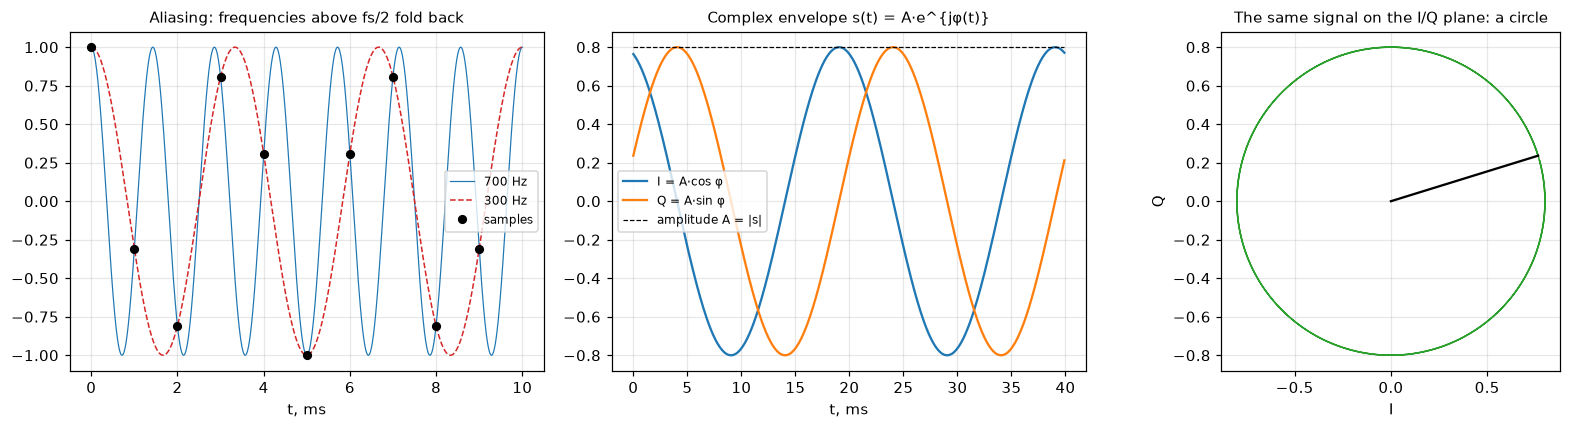

Aliasing: a 700 Hz tone at fs = 1000 Hz → FFT peak at 300 Hz (theory |f − fs| = 300 Hz)
Frequency = rate of change of phase: dφ/dt / 2π = 50.00 Hz (set to 50)
Decibels: power ×2 → +3.01 dB, ×10 → +10 dB, ×1000 → +30 dB; amplitude ×2 → +6.02 dB (power ×4)
dBm — power relative to 1 mW: 1 mW = 0 dBm, 1 W = 30 dBm, 100 mW (Wi-Fi) = 20 dBm, 1 pW = −90 dBm


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
# sampling and aliasing: a 700 Hz tone at fs = 1000 Hz is indistinguishable from 300 Hz
fs, f_true = 1000, 700
tf = np.linspace(0, 0.01, 2000); ts = np.arange(0, 0.01, 1 / fs)
ax[0].plot(tf * 1e3, np.cos(2 * np.pi * f_true * tf), "C0", lw=0.8, label="700 Hz")
ax[0].plot(tf * 1e3, np.cos(2 * np.pi * (fs - f_true) * tf), "C3--", lw=1, label="300 Hz")
ax[0].plot(ts * 1e3, np.cos(2 * np.pi * f_true * ts), "ko", ms=5, label="samples")
ax[0].set_xlabel("t, ms"); ax[0].legend(fontsize=8); ax[0].set_title("Aliasing: frequencies above fs/2 fold back", fontsize=10)
xs = np.cos(2 * np.pi * f_true * np.arange(1000) / fs)
f_meas = np.argmax(np.abs(np.fft.rfft(xs))) * fs / 1000

# complex envelope: I and Q are two projections of a rotating phasor
t = np.arange(0, 0.04, 1e-4); f0 = 50
s = 0.8 * np.exp(1j * (2 * np.pi * f0 * t + 0.3))
ax[1].plot(t * 1e3, s.real, "C0", label="I = A·cos φ"); ax[1].plot(t * 1e3, s.imag, "C1", label="Q = A·sin φ")
ax[1].plot(t * 1e3, np.abs(s), "k--", lw=0.8, label="amplitude A = |s|")
ax[1].set_xlabel("t, ms"); ax[1].legend(fontsize=8); ax[1].set_title("Complex envelope s(t) = A·e^{jφ(t)}", fontsize=10)
ax[2].plot(s.real, s.imag, "C2", lw=1); ax[2].plot([0, s.real[0]], [0, s.imag[0]], "k-", lw=1.5)
ax[2].set_aspect("equal"); ax[2].set_xlabel("I"); ax[2].set_ylabel("Q"); ax[2].set_title("The same signal on the I/Q plane: a circle", fontsize=10)
plt.tight_layout(); plt.show()

f_from_phase = np.mean(np.diff(np.unwrap(np.angle(s)))) / (2 * np.pi * 1e-4)
print(f"Aliasing: a {f_true} Hz tone at fs = {fs} Hz → FFT peak at {f_meas:.0f} Hz (theory |f − fs| = {abs(f_true - fs)} Hz)")
print(f"Frequency = rate of change of phase: dφ/dt / 2π = {f_from_phase:.2f} Hz (set to {f0})")
print("Decibels: power ×2 → {:+.2f} dB, ×10 → {:+.0f} dB, ×1000 → {:+.0f} dB; amplitude ×2 → {:+.2f} dB (power ×4)".format(db(2), db(10), db(1000), 20 * np.log10(2)))
print("dBm — power relative to 1 mW: 1 mW = 0 dBm, 1 W = 30 dBm, 100 mW (Wi-Fi) = 20 dBm, 1 pW = −90 dBm")

## 2. Spectrum and bandwidth
* **Spectrum, Fourier transform** — decomposition of a signal into sinusoids: $X(f)=\int x(t)e^{-j2\pi ft}dt$. Its discrete version, the **DFT**, is computed by the **FFT** algorithm in $N\log N$. For windows, leakage and resolution in detail, see `transforms_sim`, section 1.
* **Bin** — one DFT frequency cell, $f_s/N$ wide.
* **Power spectral density (PSD)** — how power is distributed over frequency. For random data, the average of $|X(f)|^2$ over many segments (Welch's method).
* **Bandwidth** — the width of the occupied frequencies. There are several definitions: null-to-null, −3 dB, 99 % of the power. It measures "how much spectrum a transmission takes".
* **Symbol rate** $R$ (baud) — symbols per second. The bandwidth cannot be smaller than $R$ (level 5): changing the signal faster means a wider spectrum.
* **Out-of-band emission, ACLR, spectral mask** — how much power lands in the neighbours. Rectangular symbols give a $\mathrm{sinc}^2$ spectrum falling as $1/f^2$: 99 % of the power occupies ~19 R. A smoothed RRC pulse fits 99 % into 1.17 R and all of the power into $(1+\beta)R$ (`ofdm_sim`, section 2).

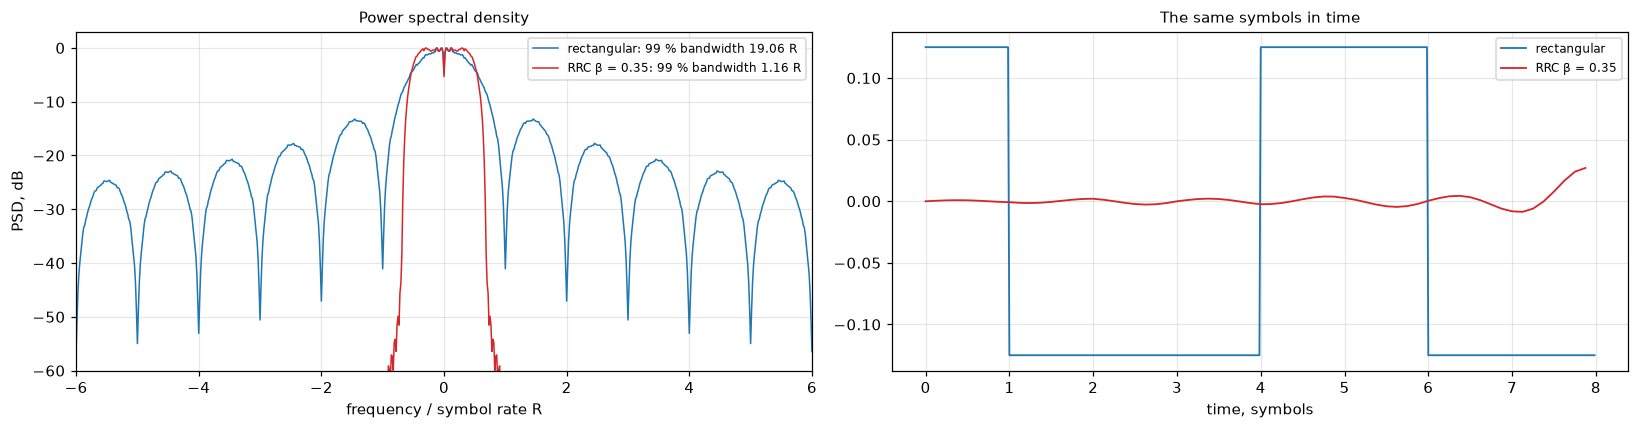

Bandwidth holding 99 % of the power: rectangular 19.1 R (theory ∫sinc²: 19.2 R), RRC 1.16 R (theory 1.17 R; the full RRC bandwidth is (1+β)·R = 1.35 R)


In [4]:
# spectrum and bandwidth: rectangular symbols vs RRC pulses
NS = 20000
sym = 1 - 2 * rng.integers(0, 2, NS).astype(float)
def shaped(pulse, sps):
    up = np.zeros(NS * sps); up[::sps] = sym; return np.convolve(up, pulse)[:NS * sps], sps
x_rect = shaped(np.ones(64) / 8, 64)                            # 64 samples/symbol: the sinc² spectrum must be visible up to ±32R
x_rrc = shaped(rrc(0.35, 8, 10), 8)
def occ_bw(xs, frac=0.99):
    x, sps = xs
    f, p = welch(x, fs=sps, nperseg=64 * sps, return_onesided=False); i = np.argsort(f); f, p = f[i], p[i]
    c = np.cumsum(p) / p.sum(); lo, hi = f[np.searchsorted(c, (1 - frac) / 2)], f[np.searchsorted(c, 1 - (1 - frac) / 2)]
    return f, p / p.max(), hi - lo
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
res = {}
for (nm, x), c in zip((("rectangular", x_rect), ("RRC β = 0.35", x_rrc)), ("C0", "C3")):
    f, p, bw = occ_bw(x); res[nm] = bw
    ax[0].plot(f, 10 * np.log10(p + 1e-12), c, lw=1, label=f"{nm}: 99 % bandwidth {bw:.2f} R")
    ax[1].plot(np.arange(8 * x[1]) / x[1], x[0][:8 * x[1]], c, lw=1.2, label=nm)
ax[0].set_xlim(-6, 6); ax[0].set_ylim(-60, 3); ax[0].set_xlabel("frequency / symbol rate R"); ax[0].set_ylabel("PSD, dB"); ax[0].legend(fontsize=8)
ax[0].set_title("Power spectral density", fontsize=10)
ax[1].set_xlabel("time, symbols"); ax[1].legend(fontsize=8); ax[1].set_title("The same symbols in time", fontsize=10)
plt.tight_layout(); plt.show()
ff = np.linspace(-200, 200, 400001); ps = np.sinc(ff) ** 2; cs = np.cumsum(ps) / ps.sum()
bw_th = ff[np.searchsorted(cs, 0.995)] - ff[np.searchsorted(cs, 0.005)]
fr = np.linspace(-1, 1, 200001); be = 0.35; af = np.abs(fr)
prc = np.where(af <= (1 - be) / 2, 1.0, np.where(af <= (1 + be) / 2, 0.5 * (1 + np.cos(np.pi / be * (af - (1 - be) / 2))), 0.0))
cr = np.cumsum(prc) / prc.sum(); bw_rc = fr[np.searchsorted(cr, 0.995)] - fr[np.searchsorted(cr, 0.005)]
print(f"Bandwidth holding 99 % of the power: rectangular {res[list(res)[0]]:.1f} R (theory ∫sinc²: {bw_th:.1f} R), RRC {res[list(res)[1]]:.2f} R (theory {bw_rc:.2f} R; the full RRC bandwidth is (1+β)·R = 1.35 R)")

## 3. Noise and link quality
* **AWGN** (additive white Gaussian noise) — noise that is added to the signal, the same at all frequencies and Gaussian-distributed. The basic channel model, the "ideal" case: $y=x+n$.
* **Thermal noise** — $kT=-174$ dBm/Hz at 290 K; in a bandwidth $B$ it is $kTB$. The receiver **noise figure** (NF) adds a few dB.
* **SNR** — the ratio of signal power to noise power within the signal bandwidth. **$E_s/N_0$** — symbol energy over noise spectral density. **$E_b/N_0$** — the same per data bit: $E_b/N_0=\frac{E_s/N_0}{\log_2M\cdot R_{code}}$. $E_b/N_0$ is what makes a fair comparison between systems with different modulations and codes (all BER curves in `ldpc_sim`, `turbo_sim`).
* **BER, SER, FER/BLER** — bit, symbol and frame (block) error probabilities. For BPSK in AWGN, $\mathrm{BER}=Q(\sqrt{2E_b/N_0})$, where $Q$ is the Gaussian tail.
* **EVM** (error vector magnitude) — the RMS deviation of the received constellation points from the ideal ones, in % or dB. In AWGN, $\mathrm{EVM}=1/\sqrt{\mathrm{SNR}}$. Handy for judging RF impairments (`ofdm_sim`, sections 4–5).
* **Shannon capacity** — $C=B\log_2(1+\mathrm{SNR})$: no more can be sent without errors. **Spectral efficiency** $\eta=C/B$ bit/s/Hz. The minimum $E_b/N_0=(2^\eta-1)/\eta$; as $\eta\to0$ it is $\ln2=-1.59$ dB — **the Shannon limit**.

The middle plot is the main map of communications: the dots show how much energy per bit uncoded modulations need, the curve how much is needed in principle. The ~8 dB gap is closed by codes (level 11).

Thermal noise kT at 290 K: -174.0 dBm/Hz; in a 20 MHz band: -101.0 dBm; with a 7 dB receiver noise figure: -94.0 dBm


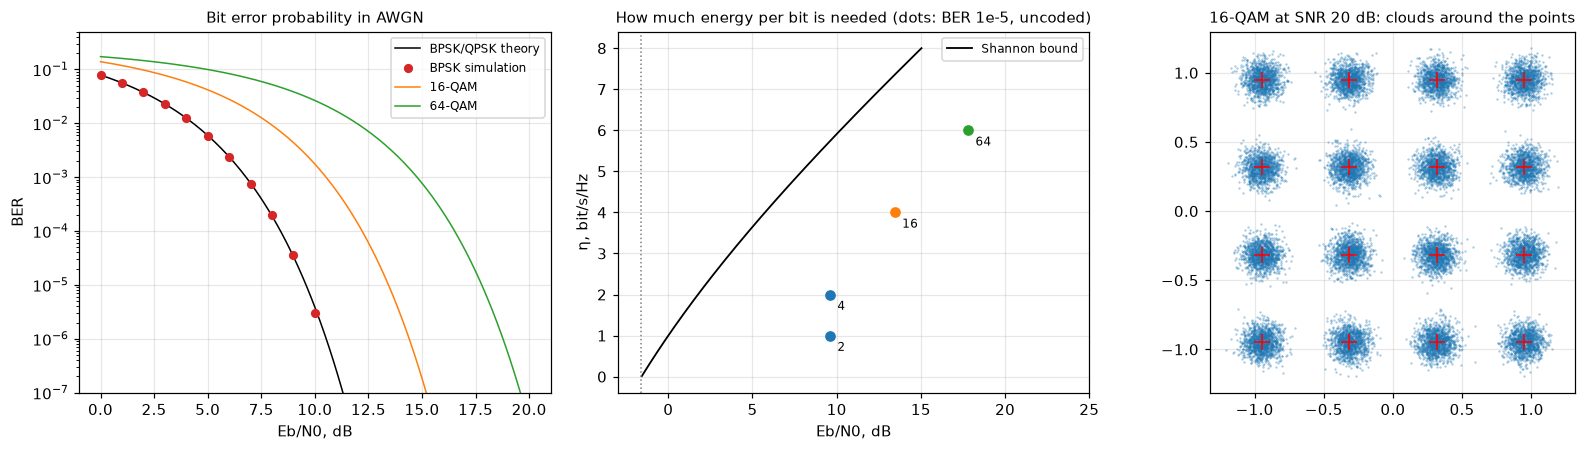

  BPSK, Eb/N0 = 4 dB: BER simulation 1.25e-02, theory 1.25e-02
  BPSK, Eb/N0 = 8 dB: BER simulation 1.97e-04, theory 1.91e-04
  BPSK, Eb/N0 = 10 dB: BER simulation 3.00e-06, theory 3.87e-06
Shannon limit as η → 0: Eb/N0 = ln 2 = -1.59 dB; for BER 1e-5 without a code one needs: BPSK 9.6 dB, QPSK 9.6 dB, 16-QAM 13.4 dB, 64-QAM 17.8 dB
  at η = 2 (QPSK) Shannon needs 1.8 dB — the 7.8 dB margin is exactly what turbo and LDPC codes recover
EVM of 16-QAM at SNR 20 dB: -20.0 dB = 9.9 % (theory: EVM = 1/√SNR = −20 dB = 10 %)


In [5]:
# thermal noise
k_B, T0 = 1.380649e-23, 290
print(f"Thermal noise kT at 290 K: {10*np.log10(k_B*T0*1e3):.1f} dBm/Hz; in a 20 MHz band: {10*np.log10(k_B*T0*20e6*1e3):.1f} dBm; with a 7 dB receiver noise figure: {10*np.log10(k_B*T0*20e6*1e3)+7:.1f} dBm")

# BPSK BER: simulation vs Q(√(2Eb/N0))
ebn0 = np.arange(0, 11)
ber_sim = []
for e in ebn0:
    nb = 2_000_000; b = rng.integers(0, 2, nb); x = 1 - 2 * b
    y = x + rng.standard_normal(nb) * np.sqrt(1 / (2 * 10 ** (e / 10)))
    ber_sim.append(np.mean((y < 0) != b))
ber_qam = lambda M, g: 4 / np.log2(M) * (1 - 1 / np.sqrt(M)) * Q(np.sqrt(3 * np.log2(M) * g / (M - 1)))
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
eb = np.linspace(0, 20, 200); g = 10 ** (eb / 10)
ax[0].semilogy(eb, Q(np.sqrt(2 * g)), "k-", lw=1, label="BPSK/QPSK theory")
ax[0].semilogy(ebn0, np.maximum(ber_sim, 1e-7), "C3o", ms=5, label="BPSK simulation")
for M, c in ((16, "C1"), (64, "C2")):
    ax[0].semilogy(eb, ber_qam(M, g), c, lw=1, label=f"{M}-QAM")
ax[0].set_ylim(1e-7, 0.5); ax[0].set_xlabel("Eb/N0, dB"); ax[0].set_ylabel("BER"); ax[0].legend(fontsize=8)
ax[0].set_title("Bit error probability in AWGN", fontsize=10)

# Shannon: the minimum Eb/N0 for spectral efficiency η
eta = np.linspace(0.01, 8, 400)
ax[1].plot(10 * np.log10((2 ** eta - 1) / eta), eta, "k-", lw=1.2, label="Shannon bound")
ax[1].axvline(10 * np.log10(np.log(2)), color="gray", ls=":", lw=1)
need = {}
for M, bits, c in ((2, 1, "C0"), (4, 2, "C0"), (16, 4, "C1"), (64, 6, "C2")):
    f = (lambda gg: Q(np.sqrt(2 * gg))) if M <= 4 else (lambda gg, M=M: ber_qam(M, gg))
    lo, hi = 0.0, 40.0
    for _ in range(60):
        mid = (lo + hi) / 2; lo, hi = (mid, hi) if f(10 ** (mid / 10)) > 1e-5 else (lo, mid)
    need[M] = hi; ax[1].plot(hi, bits, c + "o", ms=6); ax[1].annotate(f"{M}", (hi, bits), textcoords="offset points", xytext=(5, -10), fontsize=8)
ax[1].set_xlabel("Eb/N0, dB"); ax[1].set_ylabel("η, bit/s/Hz"); ax[1].set_xlim(-3, 25); ax[1].legend(fontsize=8)
ax[1].set_title("How much energy per bit is needed (dots: BER 1e-5, uncoded)", fontsize=10)

# EVM and SNR
c16 = qam_const(16); lab = rng.integers(0, 16, 20000)
ys = c16[lab] + crandn(20000, rng) * 10 ** (-20 / 20)
ax[2].plot(ys.real, ys.imag, ".", ms=1, alpha=0.4); ax[2].plot(c16.real, c16.imag, "r+", ms=10)
ax[2].set_aspect("equal"); ax[2].set_title("16-QAM at SNR 20 dB: clouds around the points", fontsize=10)
plt.tight_layout(); plt.show()

for e in (4, 8, 10):
    print(f"  BPSK, Eb/N0 = {e} dB: BER simulation {ber_sim[e]:.2e}, theory {Q(np.sqrt(2*10**(e/10))):.2e}")
print(f"Shannon limit as η → 0: Eb/N0 = ln 2 = {10*np.log10(np.log(2)):.2f} dB; for BER 1e-5 without a code one needs: " + ", ".join(f"{M}-QAM {v:.1f} dB" if M > 4 else f"{'BPSK' if M == 2 else 'QPSK'} {v:.1f} dB" for M, v in need.items()))
print(f"  at η = 2 (QPSK) Shannon needs {10*np.log10(3/2):.1f} dB — the {need[4]-10*np.log10(3/2):.1f} dB margin is exactly what turbo and LDPC codes recover")
print(f"EVM of 16-QAM at SNR 20 dB: {10*np.log10(np.mean(np.abs(ys - c16[lab])**2)):.1f} dB = {100*np.sqrt(np.mean(np.abs(ys - c16[lab])**2)):.1f} % (theory: EVM = 1/√SNR = −20 dB = 10 %)")

## 4. Modulation
* **Symbol** — one complex number sent per interval $T=1/R$; it carries $\log_2M$ bits.
* **Constellation** — the set of $M$ allowed symbols on the I/Q plane. **BPSK** ($\pm1$), **QPSK** (4 points on a circle, 2 bits), **M-QAM** (a square grid: 16-QAM — 4 bits, 64-QAM — 6 bits), **PSK** (points on a circle). In LoRa a symbol is not a point but a chirp shift (**CSS**, chirp spread spectrum, `lora_sim`).
* **Gray code** — a labelling of the points in which nearest neighbours differ in one bit. The most frequent error (confusing neighbours) then corrupts only 1 bit.
* **Hard decision** — the receiver picks the nearest point and outputs bits. **Soft decision** — it also outputs a confidence.
* **LLR** (log-likelihood ratio) — $L=\ln\frac{P(b=0\mid y)}{P(b=1\mid y)}$; for BPSK in AWGN, $L=2y/\sigma^2$. The sign is the decision, the magnitude the reliability. The LLR is the language in which the demodulator talks to the decoder (`ldpc_sim` section 5, `turbo_sim`). The right plot checks that it is an honest probability: $P(b=0\mid L)=1/(1+e^{-L})$.

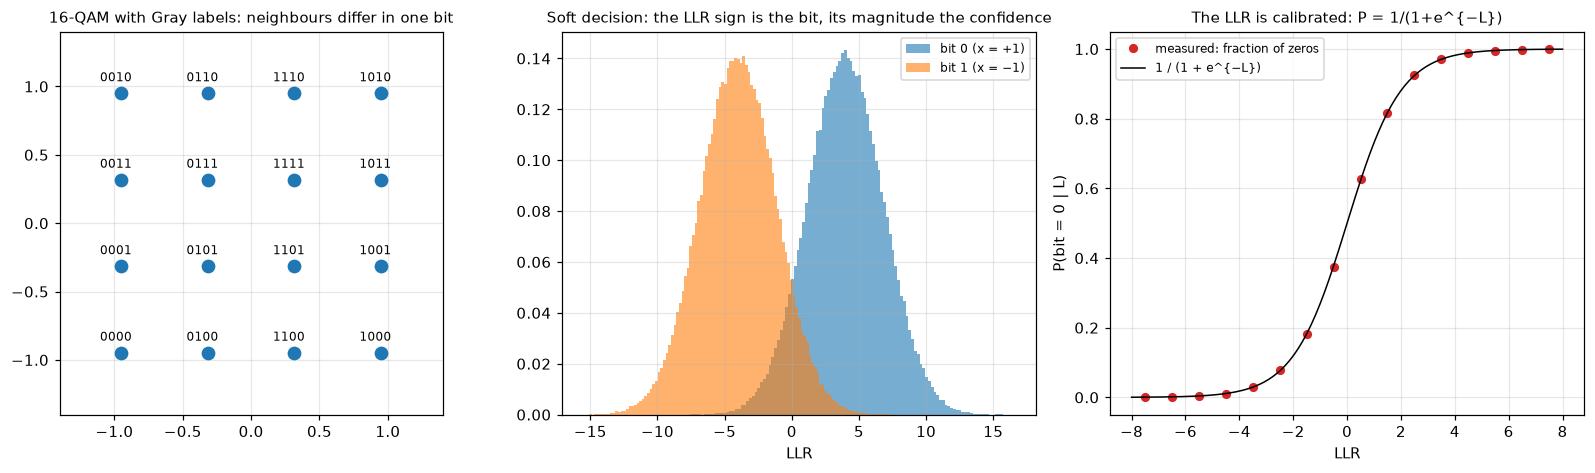

All 24 nearest-neighbour pairs of 16-QAM differ in exactly one bit: True
LLR calibration: max |measured − 1/(1+e^(−L))| = 0.003
Hard-decision errors among |L| < 1: 0.37, among |L| > 6: 8.7e-04 — the decoder should trust them differently


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
c16 = qam_const(16)
ax[0].plot(c16.real, c16.imag, "C0o", ms=8)
for i, p in enumerate(c16):
    ax[0].annotate(format(i, "04b"), (p.real, p.imag), textcoords="offset points", xytext=(-14, 8), fontsize=8)
ax[0].set_aspect("equal"); ax[0].set_xlim(-1.4, 1.4); ax[0].set_ylim(-1.4, 1.4)
ax[0].set_title("16-QAM with Gray labels: neighbours differ in one bit", fontsize=10)

# LLR for BPSK: L = 2y/σ²; checking that it is an honest log of a probability ratio
sig2 = 0.5; nb = 400000; b = rng.integers(0, 2, nb); y = (1 - 2 * b) + rng.standard_normal(nb) * np.sqrt(sig2)
L = 2 * y / sig2
ax[1].hist(L[b == 0], 120, density=True, alpha=0.6, label="bit 0 (x = +1)"); ax[1].hist(L[b == 1], 120, density=True, alpha=0.6, label="bit 1 (x = −1)")
ax[1].set_xlabel("LLR"); ax[1].legend(fontsize=8); ax[1].set_title("Soft decision: the LLR sign is the bit, its magnitude the confidence", fontsize=10)
edges = np.linspace(-8, 8, 17); mid = (edges[1:] + edges[:-1]) / 2
p0 = np.array([np.mean(b[(L >= lo) & (L < hi)] == 0) for lo, hi in zip(edges[:-1], edges[1:])])
ax[2].plot(mid, p0, "C3o", ms=5, label="measured: fraction of zeros")
lg = np.linspace(-8, 8, 200); ax[2].plot(lg, 1 / (1 + np.exp(-lg)), "k-", lw=1, label="1 / (1 + e^{−L})")
ax[2].set_xlabel("LLR"); ax[2].set_ylabel("P(bit = 0 | L)"); ax[2].legend(fontsize=8)
ax[2].set_title("The LLR is calibrated: P = 1/(1+e^{−L})", fontsize=10)
plt.tight_layout(); plt.show()

d = np.abs(c16[:, None] - c16[None]); dmin = d[d > 1e-9].min()
nbr = np.argwhere(np.abs(d - dmin) < 1e-9)
print(f"All {len(nbr)//2} nearest-neighbour pairs of 16-QAM differ in exactly one bit: {all(bin(a ^ b).count('1') == 1 for a, b in nbr)}")
print(f"LLR calibration: max |measured − 1/(1+e^(−L))| = {np.nanmax(np.abs(p0 - 1/(1+np.exp(-mid)))):.3f}")
print(f"Hard-decision errors among |L| < 1: {np.mean((L[np.abs(L)<1] < 0) != b[np.abs(L)<1]):.2f}, among |L| > 6: {np.mean((L[np.abs(L)>6] < 0) != b[np.abs(L)>6]):.1e} — the decoder should trust them differently")

## 5. Pulses, intersymbol interference, the matched filter
* **Pulse shape** $p(t)$ — the waveform each symbol is sent with: $s(t)=\sum_kX_kp(t-kT)$.
* **Intersymbol interference (ISI)** — the tails of neighbouring pulses land on the sampling instant of the current one. It comes from a narrow channel, from multipath (level 8) or from a poor pulse.
* **The Nyquist criterion** — there is no ISI if the overall pulse passes through zero at every instant $kT$, $k\neq0$. The minimum bandwidth of such a pulse is $R/2$ on each side.
* **Raised cosine (RC), root raised cosine (RRC), roll-off** $\beta$ — RC satisfies Nyquist with bandwidth $(1+\beta)R/2$. It is split equally: RRC at the transmitter and RRC at the receiver.
* **Eye diagram** — many 2-symbol stretches of the signal overlaid. An open "eye" at the sampling instant means no ISI; a closed one means ISI.
* **Matched filter** — a filter whose impulse response is the expected pulse reversed in time, $h(t)=p^*(-t)$. It maximizes the SNR at the sampling instant: $\mathrm{SNR}=E/\sigma^2$ (the Cauchy–Schwarz inequality). Correlating with a reference (level 6) is exactly a matched filter. It is present in every receiver in the series: the CDMA correlator, LoRa dechirp, the FFT in OFDM (a matched filter for all subcarriers at once).

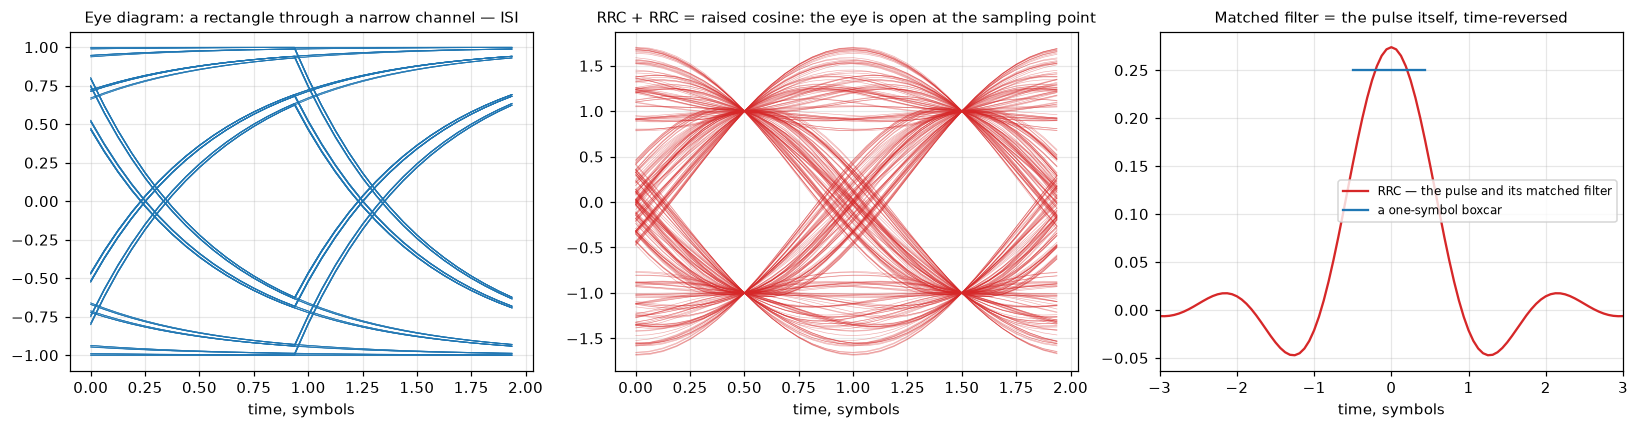

Raised cosine at the sampling instants of neighbouring symbols: max |p(kT)|/p(0) = 3.0e-04 (filter truncated to ±8 symbols)
Matched filter: output SNR 0.10 dB, theory E/σ² = 0.00 dB; the boxcar gives -0.72 dB — 0.72 dB worse (the Cauchy–Schwarz inequality)


In [7]:
SPS, NS = 16, 3000
sym = 1 - 2 * rng.integers(0, 2, NS).astype(float)
up = np.zeros(NS * SPS); up[::SPS] = sym
h_rrc = rrc(0.35, SPS, 8)
rc = np.convolve(np.convolve(up, h_rrc), h_rrc)                 # RRC at the transmitter + RRC at the receiver = raised cosine
d_rc = len(h_rrc) - 1
# a rectangular pulse through a narrow-band channel (an RC circuit)
x_rect = np.convolve(up, np.ones(SPS))[:NS * SPS]
a_lp = np.exp(-1 / (0.6 * SPS)); y_rect = np.zeros_like(x_rect); acc = 0.0
for i, v in enumerate(x_rect):
    acc = a_lp * acc + (1 - a_lp) * v; y_rect[i] = acc
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k in range(50, 400):
    ax[0].plot(np.arange(2 * SPS) / SPS, y_rect[k * SPS:(k + 2) * SPS], "C0", lw=0.4, alpha=0.4)
    ax[1].plot(np.arange(2 * SPS) / SPS, rc[d_rc + k * SPS - SPS // 2:d_rc + k * SPS - SPS // 2 + 2 * SPS], "C3", lw=0.4, alpha=0.4)
ax[0].set_title("Eye diagram: a rectangle through a narrow channel — ISI", fontsize=10)
ax[1].set_title("RRC + RRC = raised cosine: the eye is open at the sampling point", fontsize=10)
for a_ in ax[:2]: a_.set_xlabel("time, symbols")
# matched filter: an RRC pulse in white noise
sig2 = 1.0; E = np.sum(h_rrc ** 2)
snr_mf = E / sig2
box = np.ones(SPS) / np.sqrt(SPS); ctr = len(h_rrc) // 2
snr_box = (h_rrc[ctr - SPS // 2:ctr + SPS // 2] @ box) ** 2 / sig2
trials = 20000; nz = rng.standard_normal((trials, len(h_rrc))) * np.sqrt(sig2)
out_mf = (h_rrc + nz) @ h_rrc
snr_mf_meas = np.mean(out_mf) ** 2 / np.var(out_mf)
ax[2].plot(np.arange(len(h_rrc)) / SPS - 8, h_rrc, "C3", label="RRC — the pulse and its matched filter")
ax[2].plot((np.arange(SPS) - SPS // 2) / SPS, box, "C0", label="a one-symbol boxcar")
ax[2].set_xlim(-3, 3); ax[2].set_xlabel("time, symbols"); ax[2].legend(fontsize=8)
ax[2].set_title("Matched filter = the pulse itself, time-reversed", fontsize=10)
plt.tight_layout(); plt.show()

rcp = np.convolve(h_rrc, h_rrc); c0 = len(rcp) // 2
isi = np.abs(rcp[c0 + SPS * np.r_[-6:0, 1:7]]).max() / rcp[c0]
print(f"Raised cosine at the sampling instants of neighbouring symbols: max |p(kT)|/p(0) = {isi:.1e} (filter truncated to ±8 symbols)")
print(f"Matched filter: output SNR {db(snr_mf_meas):.2f} dB, theory E/σ² = {db(snr_mf):.2f} dB; the boxcar gives {db(snr_box):.2f} dB — {db(snr_mf)-db(snr_box):.2f} dB worse (the Cauchy–Schwarz inequality)")

## 6. Correlation, orthogonality, basis
* **Inner product and correlation** — $\langle x,y\rangle=\sum_nx[n]y^*[n]$: how similar two signals are. **Cross-correlation** $R_{xy}[k]=\sum_nx[n]y^*[n-k]$ — similarity at shift $k$. **Autocorrelation** — of a signal with itself. **Periodic** — with a circular shift (as after a CP or in a repeating preamble).
* **Orthogonality** — $\langle x,y\rangle=0$: the signals do not disturb each other when received by a correlator. OFDM subcarriers, Walsh codes and OCDM chirps are orthogonal sets.
* **Basis, orthonormal basis** — a set of orthogonal unit-energy functions into which any signal decomposes: $x=\sum_k\langle x,\psi_k\rangle\psi_k$ (**projections**). **Parseval**: energy is preserved. Every waveform in the series is a choice of basis (`transforms_sim`).
* **Spread spectrum (DSSS), chip** — each bit is multiplied by a fast sequence of $N$ **chips**. The receiver correlates with the same sequence (**despreading**). The signal adds coherently and the noise does not: a **processing gain** of $10\lg N$ dB (`cdma_sim`).
* **m-sequence** — the output of a maximal-length linear-feedback shift register, $2^n-1$ long. Its periodic autocorrelation is ideal: $N$ at zero and $-1$ everywhere else. CDMA synchronization, GPS.
* **Gold codes** — the sum of two "preferred" m-sequences. The cross-correlation takes only three values ($\pm17$ for $n=7$), so many users can share one band. An arbitrary pair reaches 41.
* **Zadoff–Chu (ZC), CAZAC** — $e^{-j\pi un(n+1)/N}$: Constant Amplitude and Zero periodic AutoCorrelation off the peak. LTE/NR preambles, DroneID (`ocusync_sim`). It is a discrete chirp (level 7).
* **Synchronization, acquisition** — finding the shift at which the correlation with a known sequence (a **preamble**) is maximal.

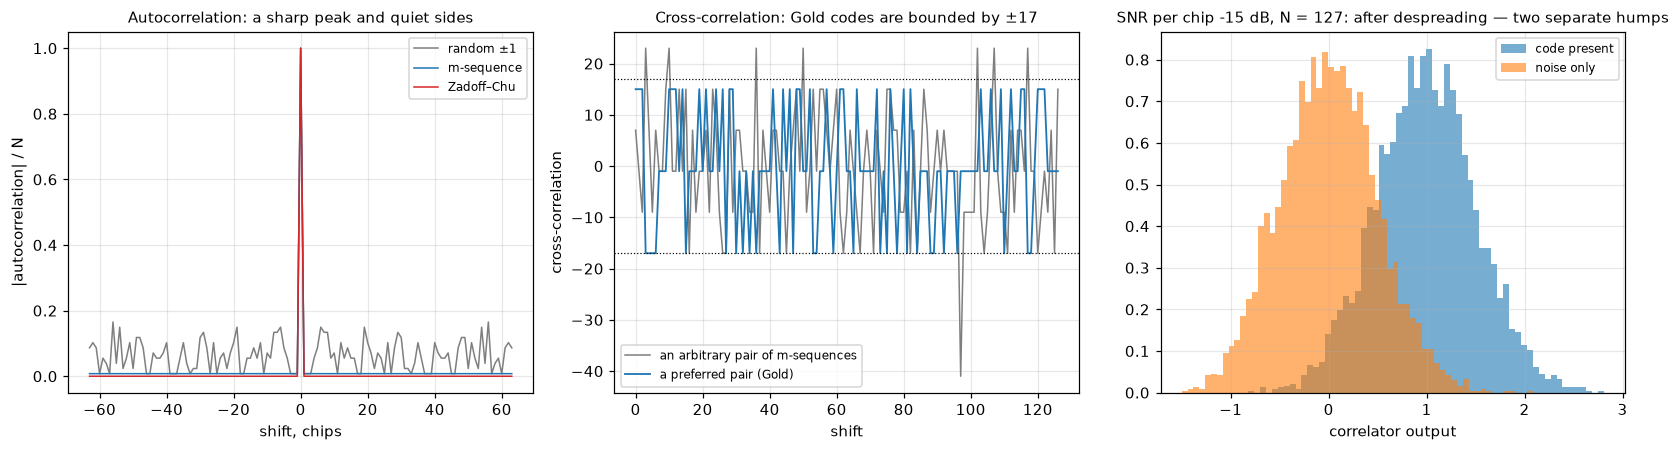

Periodic autocorrelation of the m-sequence off the peak: [-1] (theory −1); |ZC| off the peak: 4.7e-12; |ZC[n]| = 1.000…1.000 (constant amplitude: CAZAC)
Cross-correlation: Gold pair [-17, -1, 15] (theory −1, −17, 15); arbitrary pair up to 41
Processing gain: SNR per chip -15 dB → after correlation 5.8 dB (theory -15 + 10·lg 127 = 6.0 dB)
Basis: the 8 Walsh functions are orthogonal — Wᵀ·W = 8·I: True; any vector = Σ of projections: error 2.2e-16


In [8]:
u = mseq([7, 3], 7); v = mseq([7, 3, 2, 1], 7); w = mseq([7, 6, 5, 4], 7)
Nn = len(u)
zc = np.exp(-1j * np.pi * 5 * np.arange(Nn) * (np.arange(Nn) + 1) / Nn)      # Zadoff–Chu, root 5, length 127 (prime)
rnd = 1 - 2 * rng.integers(0, 2, Nn)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for x_, nm, c in ((rnd, "random ±1", "C7"), (u, "m-sequence", "C0"), (zc, "Zadoff–Chu", "C3")):
    r = np.abs(pcorr(x_, x_)) / Nn
    ax[0].plot(np.arange(-63, 64), np.roll(r, 63), c, lw=1, label=nm)
ax[0].set_xlabel("shift, chips"); ax[0].set_ylabel("|autocorrelation| / N"); ax[0].legend(fontsize=8)
ax[0].set_title("Autocorrelation: a sharp peak and quiet sides", fontsize=10)
ccg = pcorr(u, v).real; ccx = pcorr(u, w).real
ax[1].plot(ccx, "C7", lw=1, label="an arbitrary pair of m-sequences"); ax[1].plot(ccg, "C0", lw=1.2, label="a preferred pair (Gold)")
ax[1].axhline(17, color="k", ls=":", lw=0.8); ax[1].axhline(-17, color="k", ls=":", lw=0.8)
ax[1].set_xlabel("shift"); ax[1].set_ylabel("cross-correlation"); ax[1].legend(fontsize=8)
ax[1].set_title("Cross-correlation: Gold codes are bounded by ±17", fontsize=10)
# processing gain: a −15 dB-per-chip signal is pulled out by correlation
SNR_CHIP = -15; trials = 4000
rx = u[None] + rng.standard_normal((trials, Nn)) * 10 ** (-SNR_CHIP / 20)
stat = rx @ u / Nn
ax[2].hist(stat, 60, density=True, alpha=0.6, label="code present")
stat0 = (rng.standard_normal((trials, Nn)) * 10 ** (-SNR_CHIP / 20)) @ u / Nn
ax[2].hist(stat0, 60, density=True, alpha=0.6, label="noise only")
ax[2].set_xlabel("correlator output"); ax[2].legend(fontsize=8)
ax[2].set_title(f"SNR per chip {SNR_CHIP} dB, N = {Nn}: after despreading — two separate humps", fontsize=10)
plt.tight_layout(); plt.show()

print(f"Periodic autocorrelation of the m-sequence off the peak: {sorted(set(np.round(pcorr(u, u).real[1:]).astype(int).tolist()))} (theory −1); |ZC| off the peak: {np.abs(pcorr(zc, zc)[1:]).max():.1e}; |ZC[n]| = {np.abs(zc).min():.3f}…{np.abs(zc).max():.3f} (constant amplitude: CAZAC)")
print(f"Cross-correlation: Gold pair {sorted(set(np.round(ccg).astype(int).tolist()))} (theory −1, −17, 15); arbitrary pair up to {np.abs(ccx).max():.0f}")
print(f"Processing gain: SNR per chip {SNR_CHIP} dB → after correlation {db(np.mean(stat)**2/np.var(stat)):.1f} dB (theory {SNR_CHIP} + 10·lg {Nn} = {SNR_CHIP + db(Nn):.1f} dB)")
Wh = np.array([[1]])
for _ in range(3): Wh = np.block([[Wh, Wh], [Wh, -Wh]])
print(f"Basis: the 8 Walsh functions are orthogonal — Wᵀ·W = 8·I: {np.array_equal(Wh.T @ Wh, 8 * np.eye(8))}; any vector = Σ of projections: error {np.abs(Wh.T @ (Wh @ (z := rng.standard_normal(8))) / 8 - z).max():.1e}")

## 7. Quadratic phase and chirps
* **Instantaneous frequency** — $f(t)=\frac1{2\pi}\frac{d\varphi}{dt}$ (level 1) for a signal whose frequency changes.
* **Quadratic phase, linear FM, chirp** — $\varphi(t)=\pi\mu t^2$ gives a **linearly changing frequency** $f(t)=\mu t$: a "whistle" from $-B/2$ to $B/2$ over time $T$, $\mu=B/T$. Chirps are the basis of LoRa (`lora_sim`), radar, OCDM and AFDM (`ocdm_sim`, `afdm_sim`), and a quadratic phase is the basis of the Fresnel transform and diffraction (`transforms_sim`, sections 5–6).
* **Dechirp** — multiplication by a conjugate reference chirp. A copy delayed by $\tau$ turns into a **tone** at frequency $\mu\tau$, so the delay is measured with one FFT. This is how the LoRa demodulator and FMCW radar work. The flip side: a frequency offset is indistinguishable from a time shift (**delay–Doppler coupling** of a chirp, `lora_sim` section 4).
* **Pulse compression, time–bandwidth product** $BT$ — the matched filter (level 5) compresses a long chirp of duration $T$ into a peak ~$1/B$ wide. The energy of a long pulse with the resolution of a short one. The compression ratio is the **time–bandwidth product** $BT$; here $BT=200$, a 4.4 µs peak out of 1 ms.
* **Spreading factor (SF)** in LoRa — $\log_2$ of the number of chirp samples: each SF step doubles the duration and adds 3 dB of gain.

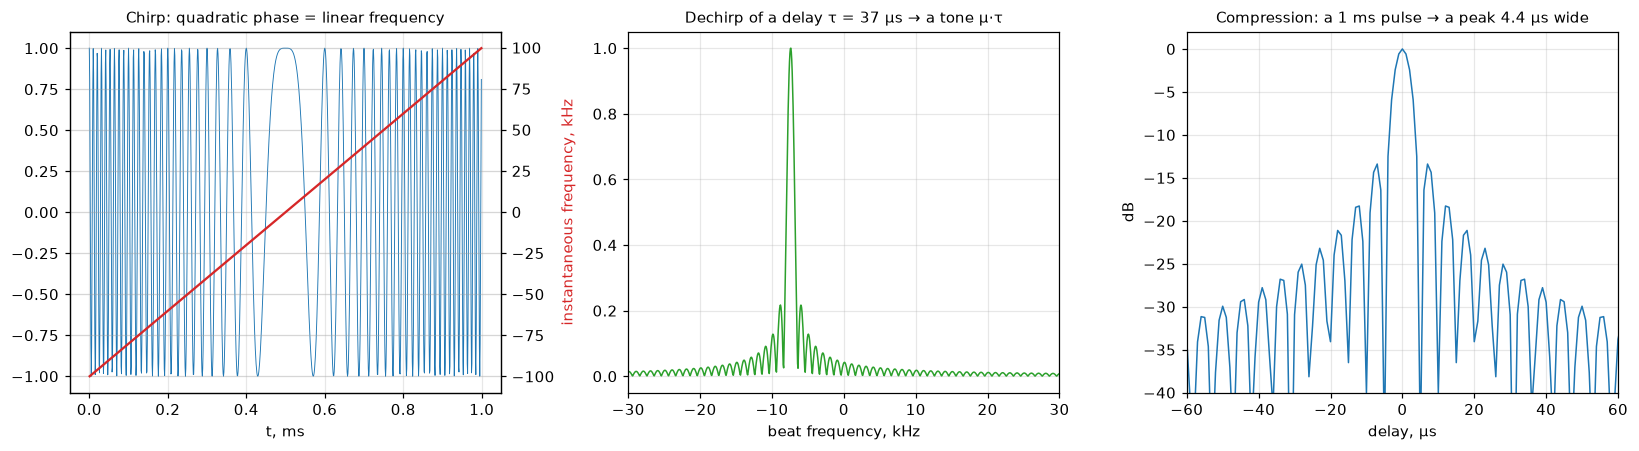

Instantaneous frequency from -99.9 to 99.7 kHz: slope μ = B/T = 200 kHz/ms
Dechirp: beat frequency -7.38 kHz → τ̂ = 36.88 µs (set to 37) — for a chirp, delay turns into frequency (LoRa, radar, AFDM)
Pulse compression: −3 dB peak width 4.38 µs (theory 0.886/B = 4.43 µs); compression ratio B·T = 200


In [9]:
# a chirp: bandwidth B over time T, a quadratic phase
FSc, Tc, Bc = 1e6, 1e-3, 200e3
tc = np.arange(int(FSc * Tc)) / FSc; mu = Bc / Tc
chirp = np.exp(1j * np.pi * mu * (tc - Tc / 2) ** 2)          # φ(t) = π·μ·t² → f(t) = μ·t
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].plot(tc * 1e3, chirp.real, "C0", lw=0.6)
a2 = ax[0].twinx(); fi = np.diff(np.unwrap(np.angle(chirp))) * FSc / (2 * np.pi)
a2.plot(tc[1:] * 1e3, fi / 1e3, "C3", lw=1.5); a2.set_ylabel("instantaneous frequency, kHz", color="C3")
ax[0].set_xlabel("t, ms"); ax[0].set_title("Chirp: quadratic phase = linear frequency", fontsize=10)
# dechirp: a delayed copy × the conjugate reference = a tone at frequency μ·τ
tau = 37e-6
rx = np.exp(1j * np.pi * mu * (tc - Tc / 2 - tau) ** 2)
beat = rx * np.conj(chirp)
F = np.abs(np.fft.fftshift(np.fft.fft(beat, 16 * len(tc)))); fF = np.fft.fftshift(np.fft.fftfreq(16 * len(tc), 1 / FSc))
f_beat = fF[np.argmax(F)]
ax[1].plot(fF / 1e3, F / F.max(), "C2", lw=1); ax[1].set_xlim(-30, 30); ax[1].set_xlabel("beat frequency, kHz")
ax[1].set_title(f"Dechirp of a delay τ = {tau*1e6:.0f} µs → a tone μ·τ", fontsize=10)
# pulse compression: the matched filter compresses T to ~1/B
mf = np.correlate(np.r_[np.zeros(len(tc)), chirp, np.zeros(len(tc))], chirp, mode="valid")
m = np.abs(mf) / np.abs(mf).max(); tm = (np.arange(len(m)) - len(tc)) / FSc
fine = np.linspace(tm[0], tm[-1], 200 * len(tm)); mi = np.interp(fine, tm, m); w3 = np.ptp(fine[mi >= 1 / np.sqrt(2)])
ax[2].plot(tm * 1e6, 20 * np.log10(m + 1e-6), "C0", lw=1); ax[2].set_xlim(-60, 60); ax[2].set_ylim(-40, 2)
ax[2].set_xlabel("delay, µs"); ax[2].set_ylabel("dB")
ax[2].set_title(f"Compression: a {Tc*1e3:.0f} ms pulse → a peak {w3*1e6:.1f} µs wide", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Instantaneous frequency from {fi[0]/1e3:.1f} to {fi[-1]/1e3:.1f} kHz: slope μ = B/T = {mu/1e6:.0f} kHz/ms")
print(f"Dechirp: beat frequency {f_beat/1e3:.2f} kHz → τ̂ = {abs(f_beat)/mu*1e6:.2f} µs (set to {tau*1e6:.0f}) — for a chirp, delay turns into frequency (LoRa, radar, AFDM)")
print(f"Pulse compression: −3 dB peak width {w3*1e6:.2f} µs (theory 0.886/B = {0.886/Bc*1e6:.2f} µs); compression ratio B·T = {Bc*Tc:.0f}")

## 8. The channel
* **Multipath** — the signal arrives over several paths (reflections from buildings, the ground) with different delays and phases: $h(\tau)=\sum_pa_p\delta(\tau-\tau_p)$. Across frequency the paths alternately add and cancel, giving **notches** in $|H(f)|$ every $1/\Delta\tau$.
* **Power delay profile (PDP), delay spread** $\tau_{rms}$ — the average power of the paths versus delay and its RMS width. EPA/EVA/ETU in `lte_sim` are standard 3GPP profiles.
* **Coherence bandwidth** $B_c\sim1/(2\pi\tau_{rms})$ — over what frequency spacing the channel "remembers" itself (the correlation falls to 0.5). If the signal bandwidth is much smaller than $B_c$, fading is **flat** (the whole signal fades at once); if larger, it is **frequency-selective** (notches inside the band, ISI).
* **Doppler** $f_D=vf_c/c$ — a frequency shift due to motion. Paths from different directions get different shifts — **Doppler spread** (the Jakes spectrum). **Coherence time** $T_c\approx0.423/f_D$ — how long the channel stays constant. Fast fading: the channel changes within a symbol or frame; slow fading: it does not.
* **Rayleigh, Rice, K-factor** — the distribution of the amplitude $|h|$. Many paths without a direct one → $h$ is complex Gaussian, $|h|$ is Rayleigh, and deep fades are common: $P(|h|^2<-20\text{ dB})=1\%$. A direct path (**LOS**) carrying a power fraction $K/(K+1)$ → Rice: at $K=5$ the fades are 20 times rarer (`ocusync_sim`, the air-to-ground channel).
* **Path loss** — in free space, $20\lg(4\pi d/\lambda)$: +6 dB for every doubling of distance. **Link budget** — transmit power + antenna gains − losses − required SNR = margin.
* **Double dispersion** — the channel spreads in both delay and Doppler at once (high-speed trains, satellites, drones). This is what `otfs_sim` and the whole DD series (level 12) are built on.

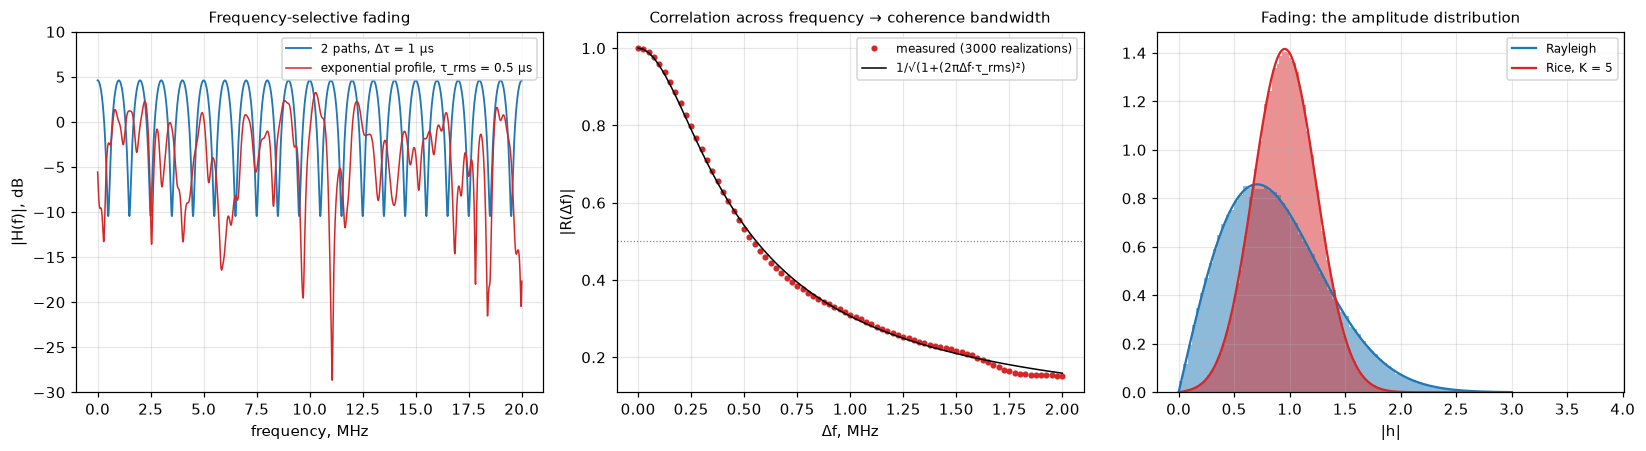

Two paths: notches every 1/Δτ = 1 MHz, depth -10.5 dB
τ_rms = 0.495 µs; the correlation falls to 0.5 at Δf = 541 kHz (theory √3/(2π·τ_rms) = 557 kHz) — this is the coherence bandwidth
Deep fades (|h|² < −20 dB): Rayleigh 1.01% (theory 1 − e^(−0.01) = 1.00%), Rice K = 5: 0.051%
Doppler: 120 km/h at 2 GHz → f_D = v·f_c/c = 222 Hz; channel correlation in time: measured 0.558 at 1.00 ms, theory J₀(2πf_D·Δt) = 0.569; coherence time ≈ 0.423/f_D = 1.90 ms
Free-space path loss 20·lg(4πd/λ): 1 km at 2.4 GHz = 100.0 dB; doubling the distance = +6 dB


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
# multipath: frequency response of two paths and of an exponential profile
f = np.linspace(0, 20e6, 2001)
H2 = np.abs(1 + 0.7 * np.exp(-2j * np.pi * f * 1e-6))
ax[0].plot(f / 1e6, 20 * np.log10(H2), "C0", lw=1.2, label="2 paths, Δτ = 1 µs")
TAU = 0.5e-6; dl = np.arange(0, 8 * TAU, 25e-9); pdp = np.exp(-dl / TAU); pdp /= pdp.sum()
hh = crandn(len(dl), rng) * np.sqrt(pdp)
Hm = np.abs(np.exp(-2j * np.pi * np.outer(f, dl)) @ hh)
ax[0].plot(f / 1e6, 20 * np.log10(Hm), "C3", lw=1, label=f"exponential profile, τ_rms = {TAU*1e6:.1f} µs")
ax[0].set_ylim(-30, 10); ax[0].set_xlabel("frequency, MHz"); ax[0].set_ylabel("|H(f)|, dB"); ax[0].legend(fontsize=8)
ax[0].set_title("Frequency-selective fading", fontsize=10)
# coherence bandwidth
dfs = np.linspace(0, 2e6, 81); R = np.zeros(len(dfs), complex)
for _ in range(3000):
    hh = crandn(len(dl), rng) * np.sqrt(pdp)
    H0 = np.exp(-2j * np.pi * np.outer(dfs, dl)) @ hh
    R += H0 * np.conj(H0[0])
R = np.abs(R) / np.abs(R[0])
tr = np.sqrt(np.sum(pdp * dl ** 2) - np.sum(pdp * dl) ** 2)
R_th = 1 / np.sqrt(1 + (2 * np.pi * dfs * tr) ** 2)
ax[1].plot(dfs / 1e6, R, "C3o", ms=3, label="measured (3000 realizations)"); ax[1].plot(dfs / 1e6, R_th, "k-", lw=1, label="1/√(1+(2πΔf·τ_rms)²)")
ax[1].axhline(0.5, color="gray", ls=":", lw=0.8); ax[1].set_xlabel("Δf, MHz"); ax[1].set_ylabel("|R(Δf)|"); ax[1].legend(fontsize=8)
ax[1].set_title("Correlation across frequency → coherence bandwidth", fontsize=10)
# envelope distribution: Rayleigh (no line of sight) and Rice (K = 5)
nsamp = 200000; K = 5
ray = np.abs(crandn(nsamp, rng))
ric = np.abs(np.sqrt(K / (K + 1)) + crandn(nsamp, rng) * np.sqrt(1 / (K + 1)))
r = np.linspace(0, 3, 300)
ax[2].hist(ray, 100, density=True, alpha=0.5, color="C0"); ax[2].plot(r, 2 * r * np.exp(-r ** 2), "C0", lw=1.5, label="Rayleigh")
sR = np.sqrt(1 / (2 * (K + 1)))
ax[2].hist(ric, 100, density=True, alpha=0.5, color="C3"); ax[2].plot(r, rice.pdf(r, np.sqrt(K / (K + 1)) / sR, scale=sR), "C3", lw=1.5, label=f"Rice, K = {K}")
ax[2].set_xlabel("|h|"); ax[2].legend(fontsize=8); ax[2].set_title("Fading: the amplitude distribution", fontsize=10)
plt.tight_layout(); plt.show()

dfi = np.linspace(0, 2e6, 20001); Ri = np.interp(dfi, dfs, R); f_half = dfi[np.argmax(Ri < 0.5)]
print(f"Two paths: notches every 1/Δτ = {1/1e-6/1e6:.0f} MHz, depth {20*np.log10(1-0.7):.1f} dB")
print(f"τ_rms = {tr*1e6:.3f} µs; the correlation falls to 0.5 at Δf = {f_half/1e3:.0f} kHz (theory √3/(2π·τ_rms) = {np.sqrt(3)/(2*np.pi*tr)/1e3:.0f} kHz) — this is the coherence bandwidth")
print(f"Deep fades (|h|² < −20 dB): Rayleigh {np.mean(ray**2 < 0.01):.2%} (theory 1 − e^(−0.01) = {1-np.exp(-0.01):.2%}), Rice K = 5: {np.mean(ric**2 < 0.01):.3%}")

# Doppler and coherence time
v, fc = 120 / 3.6, 2e9; fD = v * fc / 3e8
lags = np.linspace(0, 3e-3, 61); Kc = 32; acc = np.zeros(len(lags), complex)
for _ in range(3000):
    th = rng.uniform(0, 2 * np.pi, Kc); ph = rng.uniform(0, 2 * np.pi, Kc)
    g = np.exp(1j * (2 * np.pi * fD * np.cos(th)[None] * lags[:, None] + ph[None])).sum(1) / np.sqrt(Kc)
    acc += g * np.conj(g[0])
acc = (acc / 3000).real
print(f"Doppler: 120 km/h at 2 GHz → f_D = v·f_c/c = {fD:.0f} Hz; channel correlation in time: measured {acc[20]:.3f} at {lags[20]*1e3:.2f} ms, theory J₀(2πf_D·Δt) = {j0(2*np.pi*fD*lags[20]):.3f}; coherence time ≈ 0.423/f_D = {0.423/fD*1e3:.2f} ms")
print(f"Free-space path loss 20·lg(4πd/λ): 1 km at 2.4 GHz = {20*np.log10(4*np.pi*1e3/(3e8/2.4e9)):.1f} dB; doubling the distance = +6 dB")

## 9. Fighting the channel
* **Channel estimation, pilot** — known symbols (**pilots**: CRS in LTE, DMRS in NR, ZC in DroneID) from which the receiver measures $H$. The **LS estimate** $\hat H=Y/X_{pilot}$ is noisy and gets smoothed (interpolation, DFT smoothing, `ocusync_sim` section 5).
* **Equalizer** — removes the effect of the channel. **ZF** (zero forcing) $\hat X=Y/H$ is an exact inversion, but in a fade it divides the noise by a small $|h|$ and blows it up. **MMSE** $\hat X=\frac{H^*Y}{|H|^2+1/\mathrm{SNR}}$ is a trade-off between residual interference and noise. **LMMSE** is the same for a matrix channel where the symbols are mixed (`otfs_sim`, `ocdm_sim`).
* **Diversity** — sending the same information through independently fading copies: in time (interleaving + code), in frequency (a code across subcarriers), in space (several antennas), via multipath (RAKE, OTFS). The probability that **all** copies are in a fade falls as $\mathrm{SNR}^{-L}$. **Diversity order** $L$ is the slope of the BER curve: $L$ decades per 10 dB.
* **MRC** (maximum ratio combining) — the optimal way to combine copies: each weighted by $h_\ell^*$, so strong branches count more.
* **Interleaver** — a permutation of bits so that an error burst from one fade spreads over different codewords (`turbo_sim` section 11, `lte_sim`).

The cost of fading without diversity: BER $10^{-5}$ needs ~44 dB instead of 9.6 dB in AWGN. Two branches cut this to ~21 dB per branch, four to ~10 dB.

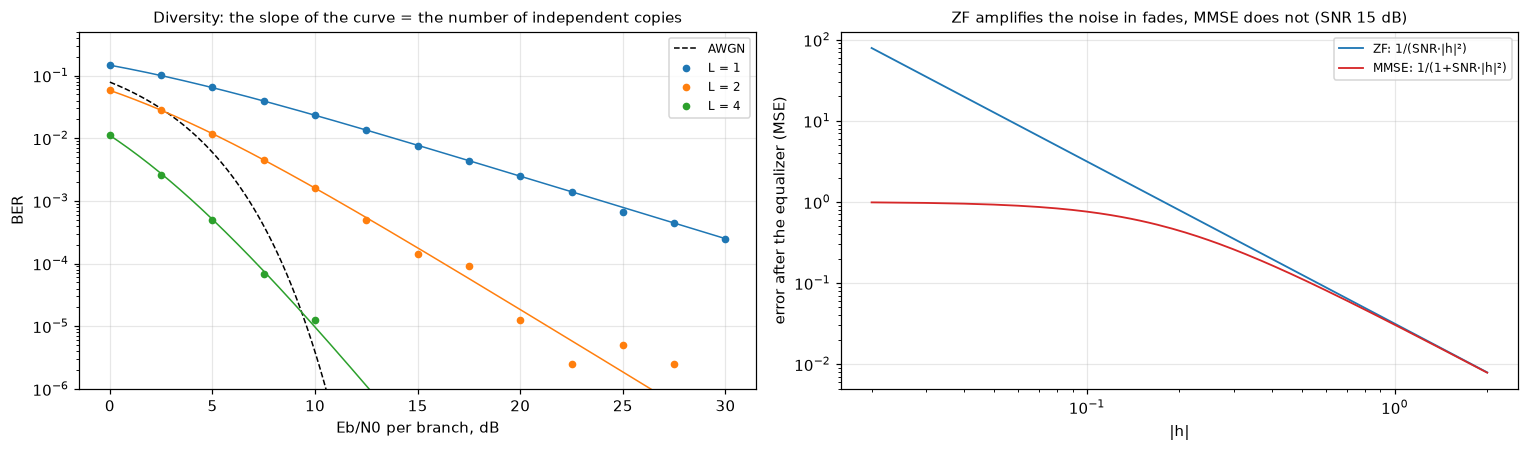

  L = 1: BER at 10 dB measured 2.38e-02, theory 2.33e-02; slope 20→30 dB: 1.00 decades per 10 dB
  L = 2: BER at 10 dB measured 1.60e-03, theory 1.60e-03; slope 20→30 dB: 1.99 decades per 10 dB
  L = 4: BER at 10 dB measured 1.25e-05, theory 9.70e-06; slope 20→30 dB: 3.99 decades per 10 dB
Without diversity BER 1e-5 needs ~44 dB (≈ 1/(4·Eb/N0)), in AWGN 9.6 dB: fading costs ~35 dB


In [11]:
# diversity: BPSK in Rayleigh fading with L branches and MRC combining
ebn0 = np.arange(0, 31, 2.5)
def ber_mrc_th(L, g):
    m = np.sqrt(g / (1 + g)); return ((1 - m) / 2) ** L * sum(comb(L - 1 + k, k) * ((1 + m) / 2) ** k for k in range(L))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
eb = np.linspace(0, 30, 300); g = 10 ** (eb / 10)
ax[0].semilogy(eb, Q(np.sqrt(2 * g)), "k--", lw=1, label="AWGN")
meas = {}
for L, c in ((1, "C0"), (2, "C1"), (4, "C2")):
    ax[0].semilogy(eb, ber_mrc_th(L, g), c, lw=1)
    bm = []
    for e in ebn0:
        nb = 400000; b = rng.integers(0, 2, nb); x = 1 - 2 * b
        h = crandn((L, nb), rng); n = crandn((L, nb), rng) * np.sqrt(1 / (2 * 10 ** (e / 10)) * 2)
        z = np.sum(np.conj(h) * (h * x + n), 0).real                  # MRC
        bm.append(np.mean((z < 0) != b))
    meas[L] = np.array(bm)
    ax[0].semilogy(ebn0, np.maximum(bm, 1e-7), c + "o", ms=4, label=f"L = {L}")
ax[0].set_ylim(1e-6, 0.5); ax[0].set_xlabel("Eb/N0 per branch, dB"); ax[0].set_ylabel("BER"); ax[0].legend(fontsize=8)
ax[0].set_title("Diversity: the slope of the curve = the number of independent copies", fontsize=10)
# equalizer: ZF vs MMSE on one subcarrier in a fade
snr = 10 ** (15 / 10); hk = np.linspace(0.02, 2, 200)
mse_zf = 1 / (snr * hk ** 2); mse_mmse = 1 / (1 + snr * hk ** 2)
ax[1].loglog(hk, mse_zf, "C0", lw=1.2, label="ZF: 1/(SNR·|h|²)"); ax[1].loglog(hk, mse_mmse, "C3", lw=1.2, label="MMSE: 1/(1+SNR·|h|²)")
ax[1].set_xlabel("|h|"); ax[1].set_ylabel("error after the equalizer (MSE)"); ax[1].legend(fontsize=8)
ax[1].set_title("ZF amplifies the noise in fades, MMSE does not (SNR 15 dB)", fontsize=10)
plt.tight_layout(); plt.show()
i10 = list(ebn0).index(10)
for L in (1, 2, 4):
    sl = np.log10(ber_mrc_th(L, 10 ** 2) / ber_mrc_th(L, 10 ** 3))
    print(f"  L = {L}: BER at 10 dB measured {meas[L][i10]:.2e}, theory {ber_mrc_th(L, 10):.2e}; slope 20→30 dB: {sl:.2f} decades per 10 dB")
print(f"Without diversity BER 1e-5 needs ~{10*np.log10(1/(4*1e-5)):.0f} dB (≈ 1/(4·Eb/N0)), in AWGN 9.6 dB: fading costs ~35 dB")

## 10. Multicarrier transmission
* **OFDM, subcarrier, spacing** $\Delta f$ — the band is split into $N$ narrow **subcarriers**, each carrying its own QAM symbol; the modulator is an IFFT and the demodulator an FFT. A subcarrier narrower than the coherence bandwidth → the channel is flat on it, and the equalizer is one division (`ofdm_sim`, `lte_sim`).
* **Cyclic prefix (CP)** — a copy of the end of the symbol placed before its start. As long as the channel delays are shorter than the CP, linear convolution with the channel becomes **circular**, and the FFT diagonalizes it exactly: $Y_k=H_kX_k$ (check: error $10^{-15}$; without a CP, ~0.2).
* **ICI** (inter-carrier interference) — leakage between subcarriers when orthogonality is broken: by a frequency offset, Doppler, phase noise, a window outside the CP.
* **CFO, STO** — carrier frequency offset and symbol timing offset; they are estimated by **synchronization** (`ofdm_sim` section 3, `ocusync_sim` section 3).
* **Resource grid, resource element, OFDMA** — a "time × subcarrier" grid; different users get different cells.
* **Peak-to-average power ratio (PAPR), CCDF** — the ratio of peak instantaneous power to mean power. A sum of many independent subcarriers is nearly Gaussian: peaks of 9–10 dB vs ~4 dB for a single carrier. The **CCDF** is the probability of exceeding a threshold. Peaks force the amplifier to run with back-off (**IBO**) and low efficiency (`ofdm_sim` section 5).
* **SC-FDMA, SC-FDE** — a single carrier with the same CP and frequency-domain equalizer: the peak-to-average ratio of a single carrier (the LTE uplink; OCDM ≡ SC-FDE in `ocdm_sim`).
* **Numerology** — choosing $\Delta f$ and the CP for the channel: $\Delta f=15\cdot2^\mu$ kHz in 5G NR (`ofdm_sim` section 7).

With CP: max|Y − H·X| = 1.4e-15; without CP: 0.23 — intersymbol interference and loss of orthogonality (ICI)


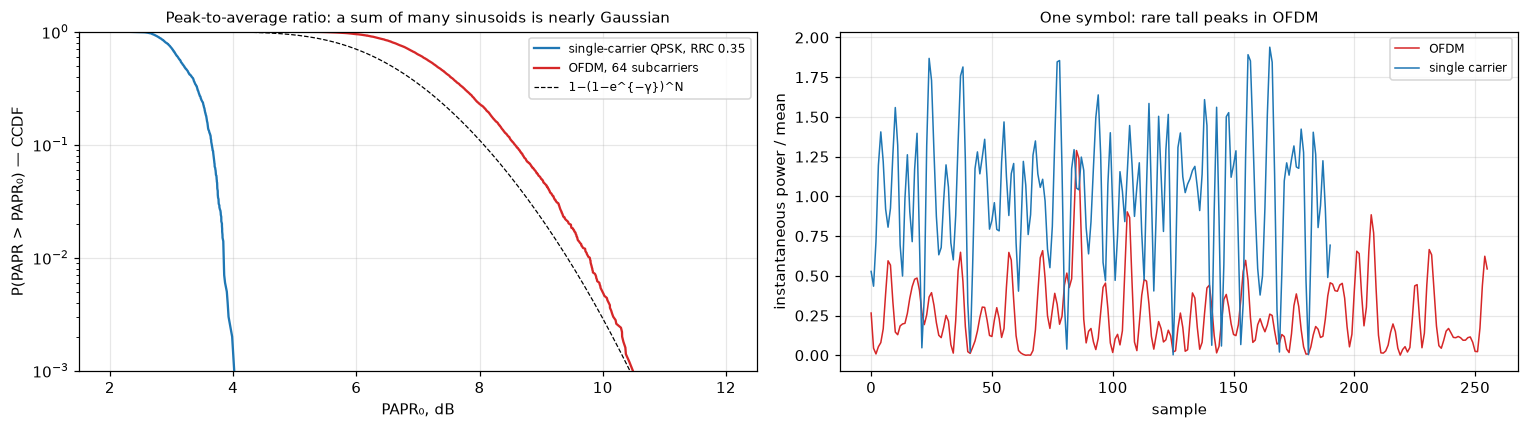

PAPR exceeded in 1 % of symbols: single carrier 3.8 dB, OFDM 9.8 dB (Nyquist theory 9.4 dB)


In [12]:
# the CP turns linear convolution into circular → Y = H·X element-wise
Nf, Ncp = 64, 8
X = (1 - 2 * rng.integers(0, 2, Nf)) + 1j * (1 - 2 * rng.integers(0, 2, Nf))
x = np.fft.ifft(X); tx = np.r_[x[-Ncp:], x]
h = crandn(6, rng) * np.exp(-np.arange(6) / 2)
rx = np.convolve(tx, h)[Ncp:Ncp + Nf]
Y = np.fft.fft(rx); H = np.fft.fft(h, Nf)
rx_nocp = np.convolve(x, h)[:Nf]
print(f"With CP: max|Y − H·X| = {np.abs(Y - H*X).max():.1e}; without CP: {np.abs(np.fft.fft(rx_nocp) - H*X).max():.2f} — intersymbol interference and loss of orthogonality (ICI)")

# peak-to-average ratio: a single carrier vs OFDM
def papr(x): return 10 * np.log10(np.max(np.abs(x) ** 2, -1) / np.mean(np.abs(x) ** 2, -1))
S, N, OSf = 5000, 64, 4
qp = ((1 - 2 * rng.integers(0, 2, (S, N))) + 1j * (1 - 2 * rng.integers(0, 2, (S, N)))) / np.sqrt(2)
G = np.zeros((S, N * OSf), complex); G[:, :N // 2] = qp[:, :N // 2]; G[:, -N // 2:] = qp[:, N // 2:]
p_ofdm = papr(np.fft.ifft(G, axis=1))
SPS = 4; up = np.zeros((S, N * SPS), complex); up[:, ::SPS] = qp; hr = rrc(0.35, SPS, 8)
sc = np.array([np.convolve(r, hr)[len(hr):len(hr) + N * SPS - len(hr)] for r in up[:1000]])
p_sc = papr(sc)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for p, nm, c in ((p_sc, "single-carrier QPSK, RRC 0.35", "C0"), (p_ofdm, "OFDM, 64 subcarriers", "C3")):
    ps = np.sort(p); ax[0].semilogy(ps, 1 - np.arange(len(ps)) / len(ps), c, lw=1.5, label=nm)
gg = np.linspace(2, 12, 200); ax[0].semilogy(gg, 1 - (1 - np.exp(-10 ** (gg / 10))) ** N, "k--", lw=0.8, label="1−(1−e^{−γ})^N")
ax[0].set_ylim(1e-3, 1); ax[0].set_xlabel("PAPR₀, dB"); ax[0].set_ylabel("P(PAPR > PAPR₀) — CCDF"); ax[0].legend(fontsize=8)
ax[0].set_title("Peak-to-average ratio: a sum of many sinusoids is nearly Gaussian", fontsize=10)
xo = np.fft.ifft(G[0]) * np.sqrt(N * OSf); ax[1].plot(np.abs(xo) ** 2, "C3", lw=1, label="OFDM")
ax[1].plot(np.abs(sc[0] / np.sqrt(np.mean(np.abs(sc[0]) ** 2))) ** 2, "C0", lw=1, label="single carrier")
ax[1].set_xlabel("sample"); ax[1].set_ylabel("instantaneous power / mean"); ax[1].legend(fontsize=8)
ax[1].set_title("One symbol: rare tall peaks in OFDM", fontsize=10)
plt.tight_layout(); plt.show()
print(f"PAPR exceeded in 1 % of symbols: single carrier {np.quantile(p_sc, 0.99):.1f} dB, OFDM {np.quantile(p_ofdm, 0.99):.1f} dB (Nyquist theory {gg[np.argmin(np.abs(1-(1-np.exp(-10**(gg/10)))**N - 0.01))]:.1f} dB)")

## 11. Error-correcting coding
* **Channel code, redundancy, rate** $R=k/n$ — $n-k$ check bits are added to $k$ data bits, and a **codeword** of length $n$ is sent.
* **Parity check, syndrome** — the checks $Hc^T=0$ (matrix $H$). If reception violated the checks, the **syndrome** $s=Hr^T\neq0$ points to an error; for the Hamming (7,4) code it points directly to its position.
* **Hamming distance** $d_{min}$ — the minimum number of differing bits between codewords; the code corrects $\lfloor(d-1)/2\rfloor$ errors. For (7,4), $d=3$.
* **CRC** — a code only for **detecting** errors in a frame (the "accept / request a retransmission" decision, HARQ).
* **Coding gain** — how many dB less $E_b/N_0$ is needed with the code at the same BER. Hamming (7,4): ~1 dB with hard decisions, ~2.5 dB with soft ones (level 4) — soft decisions are almost always worth ~2 dB.
* **Iterative decoding, extrinsic information** — decoders or graph nodes repeatedly exchange LLRs, passing on only *new* knowledge (`ldpc_sim` sections 6–8, `turbo_sim` section 6).
* **Waterfall, error floor, threshold** — the BER curve of a modern code drops steeply after the **threshold** (the waterfall) and may level off at a **floor** caused by weak code structures. The threshold is predicted by the **EXIT chart** and **density evolution**.
* **LDPC, turbo code** — codes operating within ~1 dB of Shannon: a sparse parity-check matrix with a BP decoder (`ldpc_sim`), two convolutional codes with an interleaver (`turbo_sim`).
* **Rate matching** — puncturing or repeating coded bits to fit the resource size (`ocusync_sim` section 6).

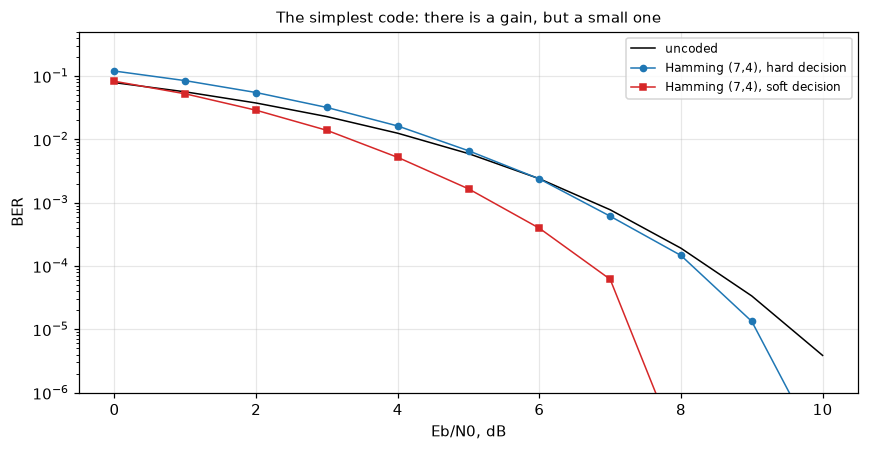

Minimum Hamming distance: 3 (corrects ⌊(d−1)/2⌋ = 1 error); rate R = 4/7 = 0.57
Eb/N0 for BER 1e-4: uncoded 9.2 dB, hard 8.2 dB, soft 6.7 dB → coding gain 1.1 and 2.5 dB
For comparison: the LTE turbo code and LDPC (turbo_sim, ldpc_sim) give ~7–8 dB of gain at BER 1e-4 and come within ~1 dB of Shannon


In [13]:
# Hamming code (7,4): 4 data bits + 3 parity checks, corrects one error
Gm = np.array([[1, 0, 0, 0, 1, 1, 0], [0, 1, 0, 0, 1, 0, 1], [0, 0, 1, 0, 0, 1, 1], [0, 0, 0, 1, 1, 1, 1]])
Hm = np.array([[1, 1, 0, 1, 1, 0, 0], [1, 0, 1, 1, 0, 1, 0], [0, 1, 1, 1, 0, 0, 1]])
assert not (Gm @ Hm.T % 2).any()
syn2pos = {tuple(Hm[:, j]): j for j in range(7)}
CW = np.array([[int(b) for b in format(m, "04b")] for m in range(16)]) @ Gm % 2     # all 16 codewords
dH = min(np.sum(a != b) for i, a in enumerate(CW) for b in CW[i + 1:])
ebn0 = np.arange(0, 11)
ber_unc, ber_hard, ber_soft = [], [], []
for e in ebn0:
    nw = 150000; m = rng.integers(0, 2, (nw, 4)); c = m @ Gm % 2
    sig = np.sqrt(1 / (2 * (4 / 7) * 10 ** (e / 10)))                  # energy per data bit: R·Eb per coded bit
    y = (1 - 2 * c) + rng.standard_normal(c.shape) * sig
    hd = (y < 0).astype(int); s = hd @ Hm.T % 2
    for i in np.where(s.any(1))[0]:
        hd[i, syn2pos[tuple(s[i])]] ^= 1                               # the syndrome points to the error position
    ber_hard.append(np.mean(hd[:, :4] != m))
    corr = y @ (1 - 2 * CW).T; best = CW[np.argmax(corr, 1)]          # soft decision: the nearest codeword in Euclidean distance
    ber_soft.append(np.mean(best[:, :4] != m))
g = 10 ** (ebn0 / 10)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.semilogy(ebn0, Q(np.sqrt(2 * g)), "k-", lw=1, label="uncoded")
ax.semilogy(ebn0, np.maximum(ber_hard, 1e-7), "C0o-", ms=4, lw=1, label="Hamming (7,4), hard decision")
ax.semilogy(ebn0, np.maximum(ber_soft, 1e-7), "C3s-", ms=4, lw=1, label="Hamming (7,4), soft decision")
ax.set_ylim(1e-6, 0.5); ax.set_xlabel("Eb/N0, dB"); ax.set_ylabel("BER"); ax.legend(fontsize=8)
ax.set_title("The simplest code: there is a gain, but a small one", fontsize=10)
plt.tight_layout(); plt.show()
def need(b):
    b = np.array(b); i = np.argmax(b < 1e-4)
    return ebn0[i - 1] + (np.log10(b[i - 1]) + 4) / (np.log10(b[i - 1]) - np.log10(b[i])) if i > 0 else np.nan
eb_unc = 10 * np.log10(8.4)
print(f"Minimum Hamming distance: {dH} (corrects ⌊(d−1)/2⌋ = {(dH-1)//2} error); rate R = 4/7 = {4/7:.2f}")
print(f"Eb/N0 for BER 1e-4: uncoded {eb_unc:.1f} dB, hard {need(ber_hard):.1f} dB, soft {need(ber_soft):.1f} dB → coding gain {eb_unc-need(ber_hard):.1f} and {eb_unc-need(ber_soft):.1f} dB")
print("For comparison: the LTE turbo code and LDPC (turbo_sim, ldpc_sim) give ~7–8 dB of gain at BER 1e-4 and come within ~1 dB of Shannon")

## 12. The delay–Doppler domain
* **Spreading function, DD representation of the channel** — the channel as a set of points $(\tau_p,\nu_p)$ with gains $h_p$: $h(\tau,\nu)=\sum_ph_p\delta(\tau-\tau_p)\delta(\nu-\nu_p)$. It is obtained from the time–frequency response $H(t,f)$ by a 2-D Fourier transform (the **symplectic** one: time → Doppler, frequency → delay).
* **Why this is convenient** — in time–frequency the channel "boils": notches everywhere, changing every symbol (left). In delay–Doppler the same three paths are **three fixed points** (right, 100 % of the energy in 3 cells out of 2048). The channel is **sparse** and **nearly constant**, so it can be estimated from one pilot.
* **OTFS, ISFFT** — a modulation that places symbols directly on the delay–Doppler grid; the ISFFT converts to the OFDM grid (`otfs_sim`). Every symbol sees **all** paths — full diversity.
* **Fractional Doppler, Dirichlet kernel** — if the Doppler does not fall on a bin, the point spreads along Doppler (here the main cell holds 57 % of the energy). This is the main practical difficulty of OTFS: a channel-estimation floor (`otfs_sim` section 3).
* **Zak transform, quasi-periodicity** — the continuous foundation of the DD representation; with a Gaussian window the channel becomes predictable from a single pilot (`zak_sim`).
* **Embedded pilot, guard region** — a pilot pulse in the DD grid surrounded by zeros as large as the channel spread (`otfs_sim` section 5, `afdm_sim` section 5).
* **Message-passing (MP) detector** — an iterative detector that exploits the sparsity of the DD channel instead of inverting a matrix (`otfs_sim` section 6).

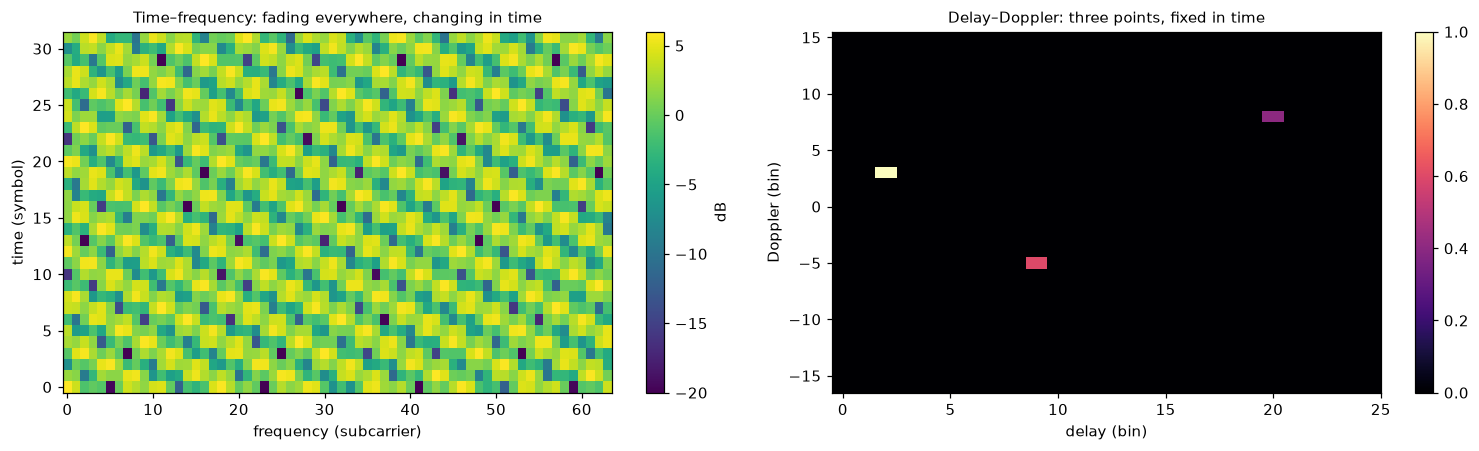

In the delay–Doppler domain 3 cells of 2048 carry 100.0% of the energy; in the time–frequency domain |H| varies from 0.00 to 2.00
A fractional Doppler of 3.4 bins: the largest cell holds 57.3% of the energy, the rest spreads along Doppler following the Dirichlet kernel (otfs_sim, section 3)


In [14]:
# the same three-path channel in two descriptions: time–frequency and delay–Doppler
M, Nd = 64, 32                                                # delay bins × Doppler bins
paths = [(1.0, 2, 3), (0.6, 9, -5), (0.4, 20, 8)]              # (gain, delay, Doppler) in bins
n = np.arange(Nd); k = np.arange(M)
H_tf = sum(a * np.exp(-2j * np.pi * k[None] * l / M) * np.exp(2j * np.pi * n[:, None] * v / Nd) for a, l, v in paths)   # H[time n, frequency k]
S_dd = np.fft.fft(np.fft.ifft(H_tf, axis=1), axis=0) / Nd       # symplectic transform: → (Doppler, delay)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
im = ax[0].imshow(20 * np.log10(np.abs(H_tf) + 1e-3), aspect="auto", origin="lower", cmap="viridis", vmin=-20, vmax=6); ax[0].grid(False)
ax[0].set_xlabel("frequency (subcarrier)"); ax[0].set_ylabel("time (symbol)"); plt.colorbar(im, ax=ax[0], label="dB")
ax[0].set_title("Time–frequency: fading everywhere, changing in time", fontsize=10)
im = ax[1].imshow(np.abs(np.fft.fftshift(S_dd, axes=0)), aspect="auto", origin="lower", cmap="magma", extent=[-0.5, M - 0.5, -Nd / 2 - 0.5, Nd / 2 - 0.5]); ax[1].grid(False)
ax[1].set_xlim(-0.5, 25); ax[1].set_xlabel("delay (bin)"); ax[1].set_ylabel("Doppler (bin)"); plt.colorbar(im, ax=ax[1])
ax[1].set_title("Delay–Doppler: three points, fixed in time", fontsize=10)
plt.tight_layout(); plt.show()
e = np.sort(np.abs(S_dd.ravel()) ** 2)[::-1]
print(f"In the delay–Doppler domain 3 cells of {M*Nd} carry {e[:3].sum()/e.sum():.1%} of the energy; in the time–frequency domain |H| varies from {np.abs(H_tf).min():.2f} to {np.abs(H_tf).max():.2f}")
p2 = [(1.0, 2, 3.4)]
H2 = sum(a * np.exp(-2j * np.pi * k[None] * l / M) * np.exp(2j * np.pi * n[:, None] * v / Nd) for a, l, v in p2)
S2 = np.abs(np.fft.fft(np.fft.ifft(H2, axis=1), axis=0) / Nd) ** 2
print(f"A fractional Doppler of 3.4 bins: the largest cell holds {S2.max()/S2.sum():.1%} of the energy, the rest spreads along Doppler following the Dirichlet kernel (otfs_sim, section 3)")

## Index of terms

| term | level | where in detail |
|---|---|---|
| ACLR, out-of-band emission | 2 | `ofdm_sim` |
| aliasing | 1 | — |
| AWGN | 3 | all |
| basis | 6 | `transforms_sim`, `ocdm_sim`, `otsm_sim` |
| BER / SER / BLER | 3 | all |
| carrier frequency offset (CFO), synchronization | 10 | `ofdm_sim`, `ocusync_sim`, `lora_sim` |
| channel estimation, pilot | 9 | `lte_sim`, `ocusync_sim`, `otfs_sim` |
| chirp, dechirp | 7 | `lora_sim`, `ocdm_sim`, `afdm_sim` |
| coherence bandwidth, delay spread | 8 | `lte_sim`, `ofdm_sim` |
| complex baseband, I/Q | 1 | all |
| constellation, QAM | 4 | `lte_sim`, `ofdm_sim` |
| correlation | 6 | `cdma_sim`, `lora_sim`, `ocusync_sim` |
| CRC | 11 | `ocusync_sim` |
| cyclic prefix (CP) | 10 | `lte_sim`, `ofdm_sim` |
| delay–Doppler (DD) | 12 | `otfs_sim`, `zak_sim`, `otsm_sim` |
| diversity | 9 | `lte_sim`, `otfs_sim` |
| Doppler, coherence time | 8 | `lte_sim`, `otfs_sim`, `ofdm_sim` |
| doubly dispersive channel | 8 | `otfs_sim`, `zak_sim`, `afdm_sim` |
| Eb/N0, Es/N0 | 3 | `ldpc_sim`, `turbo_sim`, `lte_sim` |
| EVM | 3 | `ofdm_sim` |
| EXIT chart | 11 | `ldpc_sim`, `turbo_sim` |
| eye diagram | 5 | — |
| Fourier transform, FFT | 2 | `transforms_sim` |
| fractional Doppler | 12 | `otfs_sim`, `zak_sim`, `afdm_sim` |
| Fresnel transform | 7 | `transforms_sim`, `ocdm_sim`, `afdm_sim` |
| Gold codes, m-sequence | 6 | `cdma_sim` |
| Gray code | 4 | `ofdm_sim`, `lte_sim` |
| Hamming distance, syndrome | 11 | `ldpc_sim` |
| interleaver | 9, 11 | `turbo_sim`, `lte_sim` |
| iterative decoding, extrinsic | 11 | `ldpc_sim`, `turbo_sim` |
| LLR | 4 | `ldpc_sim`, `turbo_sim`, `lte_sim` |
| matched filter | 5 | `cdma_sim`, `lora_sim` |
| MRC | 9 | `ocusync_sim`, `lte_sim` |
| multipath | 8 | `lte_sim`, `ofdm_sim`, all DD |
| numerology | 10 | `ofdm_sim` |
| OFDM, subcarrier | 10 | `ofdm_sim`, `lte_sim`, `ocusync_sim` |
| orthogonality | 6 | `ofdm_sim`, `cdma_sim`, `otsm_sim` |
| peak-to-average power ratio (PAPR), CCDF | 10 | `ofdm_sim`, `lte_sim`, `otfs_sim`, `ocdm_sim` |
| processing gain | 6 | `cdma_sim`, `lora_sim` |
| quadratic phase | 7 | `lora_sim`, `ocdm_sim`, `afdm_sim`, `transforms_sim` |
| Rayleigh / Rician fading, K-factor | 8 | `lte_sim`, `ocusync_sim` |
| root raised cosine (RRC), roll-off | 5 | `otsm_sim` (ODDM) |
| SNR | 3 | all |
| soft / hard decision | 4 | `ldpc_sim`, `turbo_sim` |
| spectral efficiency, Shannon | 3 | `ofdm_sim`, `ldpc_sim` |
| spread spectrum, chip | 6 | `cdma_sim`, `lora_sim` |
| waterfall, threshold, error floor | 11 | `ldpc_sim`, `turbo_sim` |
| wavelet | — | `transforms_sim` |
| Zadoff–Chu, CAZAC | 6 | `ocusync_sim`, `lte_sim` |
| ZF / MMSE / LMMSE | 9 | `lte_sim`, `otfs_sim`, `ocdm_sim`, `afdm_sim` |

## Suggested reading order for the series
1. **Foundations**: this notebook → `transforms_sim` (bases: Fourier, wavelets, Fresnel).
2. **Spread spectrum**: `cdma_sim` (correlation, codes, processing gain) → `lora_sim` (chirps).
3. **Codes**: `ldpc_sim` → `turbo_sim` (LLR, iterative decoding, the waterfall).
4. **Multicarrier**: `ofdm_sim` (general OFDM engineering) → `lte_sim` (a full system with 3GPP channels and a turbo code) → `ocusync_sim` (the same techniques in a drone).
5. **Channels with Doppler**: `ocdm_sim` (chirp basis, SC-FDE) → `otfs_sim` → `zak_sim` → `afdm_sim` → `otsm_sim` (the series wrap-up).

Each notebook is self-contained; the level numbers here hint at which concepts it needs beforehand.